In [1]:
from ultralytics import YOLO

model = YOLO("best.pt")

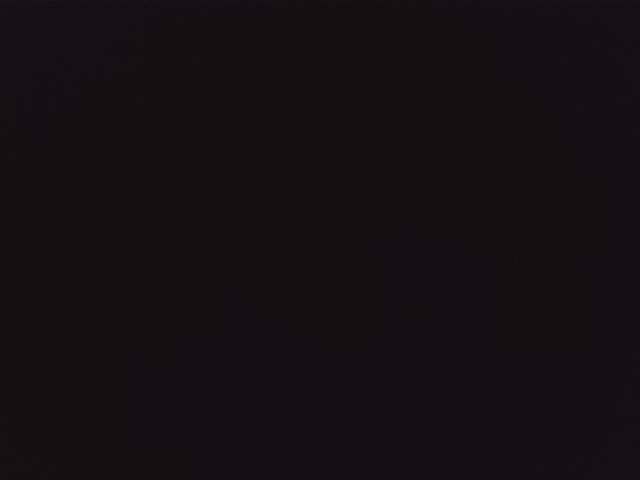

In [ ]:
import cv2
from IPython.display import display, clear_output
from PIL import Image
import time

cap = cv2.VideoCapture(0)

try:
    while cap.isOpened():
        ret, frame = cap.read()

        if not ret:
            print("Could not read from camera")
            break

        # Detect currency using your trained model
        results = model.predict(frame, conf=0.25, verbose=False)

        # Draw predictions on the frame
        annotated_frame = results[0].plot()

        # Convert BGR to RGB for Jupyter display
        annotated_frame = cv2.cvtColor(
            annotated_frame, cv2.COLOR_BGR2RGB
        )

        clear_output(wait=True)
        display(Image.fromarray(annotated_frame))

        time.sleep(0.03)

except KeyboardInterrupt:
    print("Camera stopped")

finally:
    cap.release()